In [1]:
# Group B - Assignment 1
# Problem Statement:
# Predict the price of the Uber ride from a given pickup point to the agreed drop-off location.
# Perform following tasks:
# 1. Pre-process the dataset.
# 2. Identify outliers.
# 3. Check the correlation.
# 4. Implement linear regression and random forest regression models.
# Evaluate the models and compare their respective scores like R2, RMSE, etc.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import haversine as hs
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [2]:
print("=== Loading Dataset ===")
df = pd.read_csv("uber.csv")

print("\n--- Initial Dataset Head ---")
print(df.head())

print("\n--- Dataset Info ---")
df.info()

print("\n--- Initial Shape ---")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])

=== Loading Dataset ===

--- Initial Dataset Head ---
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.

In [3]:
print("=== Step 1: Pre-processing Dataset ===")

print("\n--- Missing Values Before Handling ---")
print(df.isnull().sum())

# Drop unnecessary identifier columns
if 'Unnamed: 0' in df.columns:
    df.drop(['Unnamed: 0'], axis=1, inplace=True)
if 'key' in df.columns:
    df.drop(['key'], axis=1, inplace=True)

# Impute missing values
df['dropoff_latitude'].fillna(value=df['dropoff_latitude'].mean(), inplace=True)
df['dropoff_longitude'].fillna(value=df['dropoff_longitude'].median(), inplace=True)

print("\n--- Missing Values After Handling ---")
print(df.isnull().sum())

# Parse datetime feature
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], errors='coerce')

# Extract detailed time components
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year
df['dayofweek'] = df['pickup_datetime'].dt.dayofweek

df.drop('pickup_datetime', axis=1, inplace=True)

print("\n--- Dataset Head After Pre-processing ---")
print(df.head())

=== Step 1: Pre-processing Dataset ===

--- Missing Values Before Handling ---
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

--- Missing Values After Handling ---
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


C:\Users\DELL\AppData\Local\Temp\ipykernel_9836\2517926010.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['dropoff_latitude'].fillna(value=df['dropoff_latitude'].mean(), inplace=True)
C:\Users\DELL\AppData\Local\Temp\ipykernel_9836\2517926010.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values alwa


--- Dataset Head After Pre-processing ---
   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  hour  day  month  year  dayofweek  
0         40.723217                1    19    7      5  2015          3  
1         40.750325                1    20   17      7  2009          4  
2         40.772647                1    21   24      8  2009          0  
3         40.803349                3     8   26      6  2009          4  
4         40.761247                5    17   28      8  2014          3  


In [4]:
print("=== Step 2: Outlier Detection and Handling ===")

print("Shape before outlier removal:", df.shape)

# Filter invalid fares
df = df[df['fare_amount'] > 0]

# Filter valid geographic coordinate bounds before calculating Haversine distance
df = df[
    (df['pickup_latitude'] >= -90) & (df['pickup_latitude'] <= 90) &
    (df['dropoff_latitude'] >= -90) & (df['dropoff_latitude'] <= 90) &
    (df['pickup_longitude'] >= -180) & (df['pickup_longitude'] <= 180) &
    (df['dropoff_longitude'] >= -180) & (df['dropoff_longitude'] <= 180)
]

print("Shape after filtering valid coordinate ranges:", df.shape)

# Calculate distance using Haversine formula
travel_dist = []
for pos in range(len(df)):
    long1, lati1, long2, lati2 = [
        df['pickup_longitude'].iloc[pos],
        df['pickup_latitude'].iloc[pos],
        df['dropoff_longitude'].iloc[pos],
        df['dropoff_latitude'].iloc[pos]
    ]
    loc1 = (lati1, long1)
    loc2 = (lati2, long2)
    c = hs.haversine(loc1, loc2)
    travel_dist.append(c)

df['dist_travel_km'] = travel_dist

# Filter travel distance range (1 km to 130 km)
df = df[(df['dist_travel_km'] >= 1) & (df['dist_travel_km'] <= 130)]

print("Shape after final distance filtering:", df.shape)

=== Step 2: Outlier Detection and Handling ===
Shape before outlier removal: (200000, 11)
Shape after filtering valid coordinate ranges: (199966, 11)
Shape after final distance filtering: (163644, 12)


=== Step 3: Checking Correlation ===

--- Correlation with Target Feature (fare_amount) ---
fare_amount          1.000000
pickup_longitude     0.017521
pickup_latitude     -0.013247
dropoff_longitude    0.015541
dropoff_latitude    -0.013024
passenger_count      0.013624
hour                -0.023171
day                 -0.001903
month                0.023733
year                 0.136881
dayofweek            0.001250
dist_travel_km       0.809341
Name: fare_amount, dtype: float64


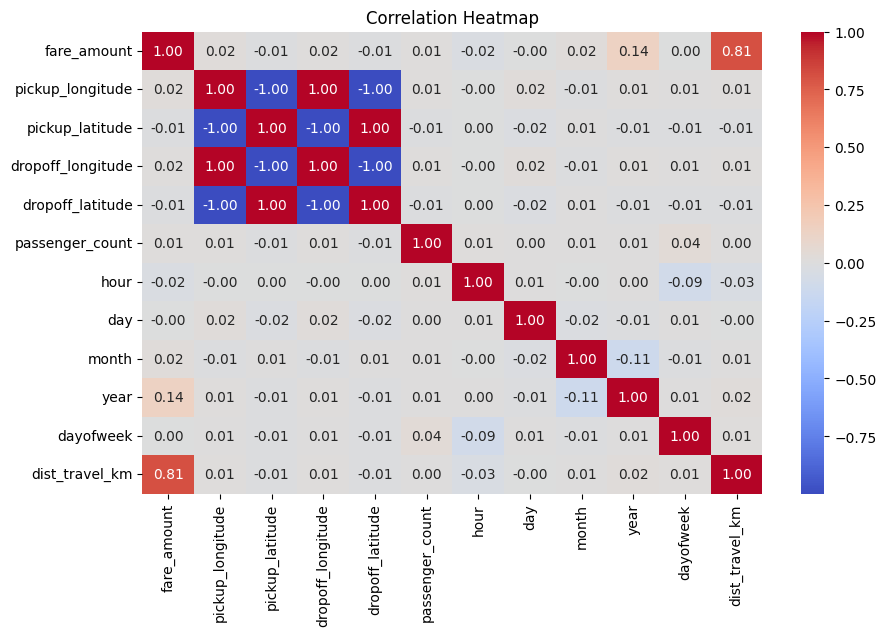

In [5]:
print("=== Step 3: Checking Correlation ===")

correlation_matrix = df.corr()
print("\n--- Correlation with Target Feature (fare_amount) ---")
print(correlation_matrix['fare_amount'])

plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [6]:
print("=== Feature Selection and Static Train-Test Split ===")

X = df[['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count', 'hour', 'day', 'month', 'year', 'dayofweek', 'dist_travel_km']]
y = df['fare_amount']

# Static split: 80% Training set, 20% Testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Static Train-Test Split Complete (80:20 Ratio):")
print("Training set shape (X_train):", X_train.shape)
print("Testing set shape (X_test):  ", X_test.shape)

=== Feature Selection and Static Train-Test Split ===
Static Train-Test Split Complete (80:20 Ratio):
Training set shape (X_train): (130915, 11)
Testing set shape (X_test):   (32729, 11)


In [7]:
print("=== Step 4: Linear Regression Model ===")

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

lr_r2 = r2_score(y_test, y_pred_lr)
lr_mse = mean_squared_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(lr_mse)

print("\n--- Linear Regression Performance ---")
print("R2 Score:", lr_r2)
print("MSE:     ", lr_mse)
print("RMSE:    ", lr_rmse)

=== Step 4: Linear Regression Model ===

--- Linear Regression Performance ---
R2 Score: 0.6774653245955442
MSE:      30.530027645056204
RMSE:     5.5253984150517335


In [8]:
print("=== Step 4: Random Forest Regression Model ===")

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

rf_r2 = r2_score(y_test, y_pred_rf)
rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(rf_mse)

print("\n--- Random Forest Regression Performance ---")
print("R2 Score:", rf_r2)
print("MSE:     ", rf_mse)
print("RMSE:    ", rf_rmse)

=== Step 4: Random Forest Regression Model ===

--- Random Forest Regression Performance ---
R2 Score: 0.8911741181906141
MSE:      10.301085227415747
RMSE:     3.20953037490156


In [9]:
print("=== Model Performance Comparison ===")
print("--------------------------------------------------")
print(f"{'Model':<25} | {'R2 Score':<10} | {'RMSE':<10}")
print("--------------------------------------------------")
print(f"{'Linear Regression':<25} | {lr_r2:<10.4f} | {lr_rmse:<10.4f}")
print(f"{'Random Forest Regression':<25} | {rf_r2:<10.4f} | {rf_rmse:<10.4f}")
print("--------------------------------------------------")

=== Model Performance Comparison ===
--------------------------------------------------
Model                     | R2 Score   | RMSE      
--------------------------------------------------
Linear Regression         | 0.6775     | 5.5254    
Random Forest Regression  | 0.8912     | 3.2095    
--------------------------------------------------
